# Verify event duration on the synthetic shape examples

**Result:** plateau-to-plateau duration captures the overall widening, delayed secondary peaks and shortening in the existing focused examples. Every actual collapse or shortening produces a shorter event at all three tested tolerances. It is a useful overall-duration response, but does not describe the number of peaks or all changes inside the event.

This verification uses **21 saved hydrographs**: 20 simple-split geometries and their common collapsed centerline. There are 20 collapse comparisons, four actual branch-shortening comparisons and two unchanged controls, evaluated at **0.5%, 1% and 2%**. No routing or full-grid sensitivity analysis was rerun. The previous temporal-spread results remain available.

Reproduce with `synthetic_experiments/investigations/event_duration_verification.py`.

**Historical supporting analysis:** this notebook retains its saved pre-selection hydraulic setup and, where applicable, earlier spread/quantile metrics. It is not an alpha=0.65 result. Use the current [results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb) for the selected setup.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'synthetic_experiments').exists())
RUN=ROOT/'synthetic_experiments/outputs/side_channel_width_length'
OUT=RUN/'event_duration_verification'
d=pd.read_csv(OUT/'comparisons.csv')
runs=pd.read_csv(OUT/'run_metrics.csv').set_index('run')
sensitivity=pd.read_csv(OUT/'threshold_sensitivity.csv')
verification=json.loads((OUT/'verification.json').read_text())
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
colors=dict(zip([.5,.2,.1,.05],plt.get_cmap('tab10').colors[:4]))
def hydro(key):
    h=pd.read_parquet(RUN/f'{key}_hydrograph.parquet')
    m=json.loads((RUN/f'{key}_metrics.json').read_text())
    dt=m['dt_seconds'];onset=round(m['buffer_hours']*3600/dt)*dt
    ok=h.time_seconds>=onset
    return (h.time_seconds[ok].to_numpy()-onset+dt/2)/3600,h.outlet_cms[ok].to_numpy()-100
print('Analytic and boundary checks:',verification['checks'])
print('Smallest settled tail:',round(verification['minimum_settled_tail_hours'],1),'hours')

Analytic and boundary checks: {'analytic_triangle': 'passed', 'pure_translation_invariance': 'passed', 'late_peak_after_flat_valley': 'passed', 'subthreshold_peak_ignored': 'passed', 'censored_tail_rejected': 'passed', 'monotonic_length_response': 'passed', 'identity_controls': 'passed', 'collapse_shortens_duration': 'passed'}
Smallest settled tail: 337.7 hours


## Exact boundary definition

Let the parent peak be $Q_{p,max}$ and the two plateau levels be $Q_0,Q_f$. For a tolerance fraction $\epsilon$:

- Start tolerance: $\epsilon(Q_{p,max}-Q_0)$.
- End tolerance: $\epsilon(Q_{p,max}-Q_f)$.
- Apply these **same absolute tolerances to parent and child**.
- Start at the first departure beyond the initial tolerance, after spin-up.
- End after the **last excursion** outside the final tolerance. This must be after the peak, and the remainder of the record must stay within tolerance for at least one hour.

$T=t_{end}-t_{start}$ and $\Delta T=100(T_{child}/T_{parent}-1)$.

In these synthetic runs both plateaus equal **100 m³/s**, so start and end tolerances are equal. A 1% endpoint means 99% recession back toward the final plateau, not 99% of peak discharge and not a cumulative-volume quantile. Crossings are interpolated between interval-average discharges placed at interval midpoints.

The same collapsed centerline appears in every collapse pair, but its measured duration varies slightly because each pair uses its own parent's amplitude to fix the common tolerance. This is intentional.

Verification checks include an analytic triangular pulse, unchanged duration under pure translation, a late peak after a completely flat valley, a subthreshold peak, and rejection of a truncated tail.

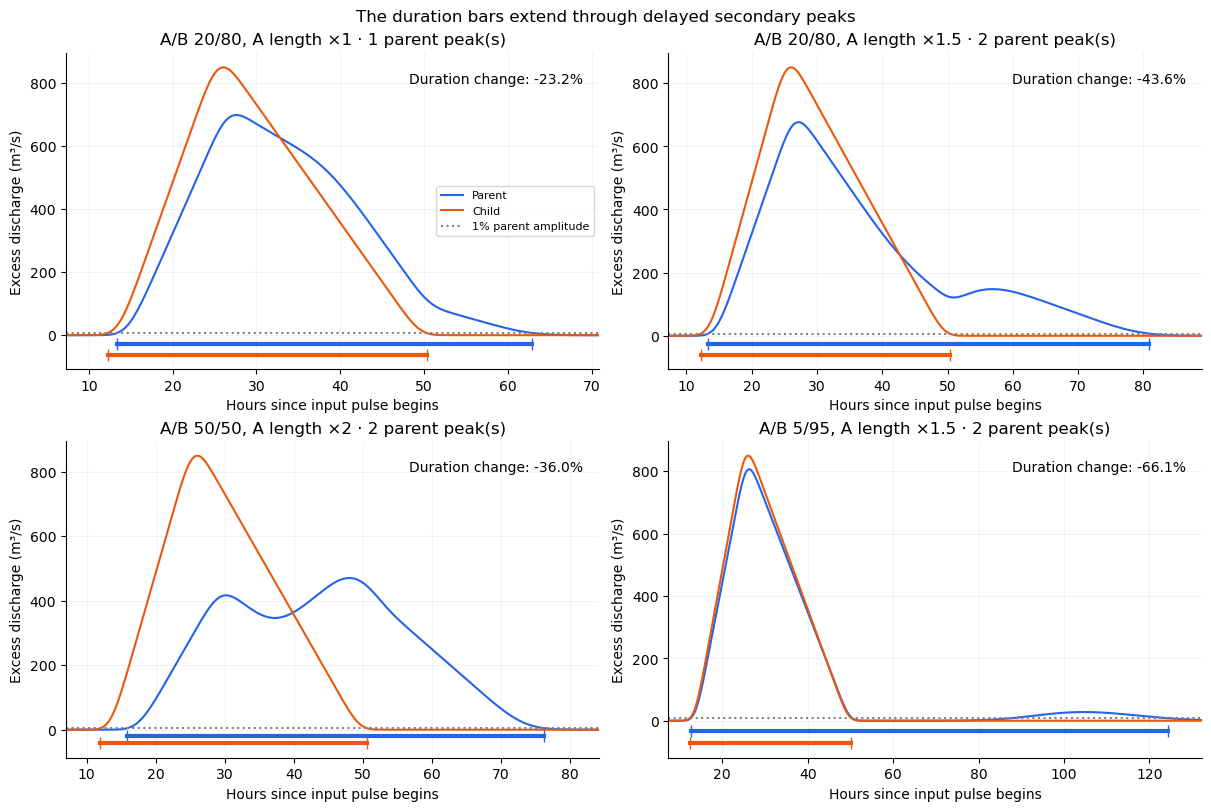

In [2]:
examples=[(.2,1.),(.2,1.5),(.5,2.),(.05,1.5)]
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for ax,(a,m) in zip(axes.flat,examples):
    row=d[(d.kind=='collapse')&(d.outer_a_fraction==a)&(d.length_multiplier==m)&(d.threshold_fraction==.01)].iloc[0]
    for role,color in [('parent','#2563eb'),('child','#ea580c')]:
        t,q=hydro(row[role]);ax.plot(t,q,color=color,label=role.capitalize())
        start=row[f'{role}_start_hours'];end=row[f'{role}_end_hours']
        y=-row.tolerance_cms*(4 if role=='parent' else 9)
        ax.plot([start,end],[y,y],color=color,lw=3,marker='|',markersize=9)
    ax.axhline(row.tolerance_cms,color='gray',ls=':',label='1% parent amplitude')
    ax.set(xlim=(max(0,min(row.parent_start_hours,row.child_start_hours)-5),max(row.parent_end_hours,row.child_end_hours)+8),
           xlabel='Hours since input pulse begins',ylabel='Excess discharge (m³/s)',
           title=f'A/B {a*100:g}/{(1-a)*100:g}, A length ×{m:g} · {int(runs.loc[row.parent,"screened_peak_count"])} parent peak(s)')
    ax.text(.97,.94,f'Duration change: {row.duration_change_pct:.1f}%',transform=ax.transAxes,ha='right',va='top')
axes.flat[0].legend(loc='center right',fontsize=8)
fig.suptitle('The duration bars extend through delayed secondary peaks')
fig.savefig(OUT/'duration_boundaries.png',dpi=160);display(fig);plt.close(fig)

## Does it recover the previous synthetic pattern?

Yes, for these focused examples. Increasing the selected branch's length increases parent event duration at every split and tolerance. Collapsing that network therefore shortens the event more strongly. The relationship continues through the transition from a broad single peak to two separate peaks.

At 1%, the rank correlation between collapse-induced duration change and temporal-spread change is **0.940**. They broadly recover the same ordering, but their numerical changes are not interchangeable: duration weights a small late pulse through its timing, while temporal spread also weights its volume.

Peak counts below use the existing prominence screen of 1% of the **input** pulse amplitude. This separate diagnostic should not be confused with the duration tolerance of 1% of the **parent outlet** amplitude.

Median threshold range: 1.13 percentage points
Largest threshold range: 4.088 percentage points
Every comparison retains its sign: True


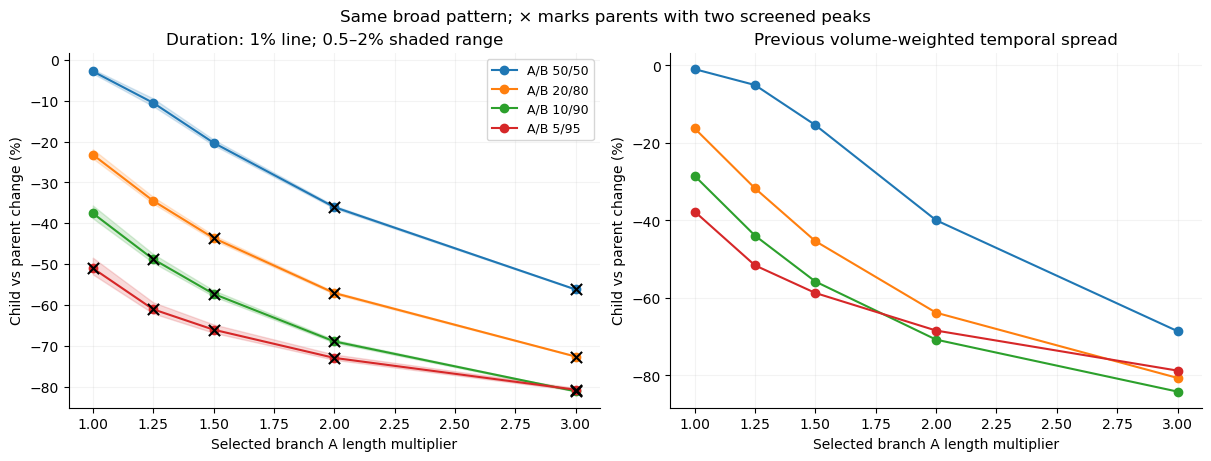

,outer_a_fraction,length_multiplier,parent_duration_hours,child_duration_hours,duration_change_pct,temporal_spread_change_pct,peak_excess_change_pct
16,0.20,1.0,49.58,38.07,-23.20,-16.26,21.64
22,0.20,1.5,67.60,38.12,-43.61,-45.35,25.63
28,0.20,3.0,139.41,38.12,-72.66,-80.65,25.63
46,0.05,1.0,77.34,37.89,-51.01,-37.72,5.37
52,0.05,1.5,111.66,37.89,-66.07,-58.73,5.37
58,0.05,3.0,197.10,37.89,-80.78,-78.77,5.37


In [3]:
collapse=d[d.kind=='collapse']
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for a,color in colors.items():
    g=collapse[collapse.outer_a_fraction==a]
    w=g.pivot(index='length_multiplier',columns='threshold_fraction',values='duration_change_pct').sort_index()
    axes[0].fill_between(w.index,w.min(axis=1),w.max(axis=1),color=color,alpha=.17)
    axes[0].plot(w.index,w[.01],'-o',color=color,label=f'A/B {a*100:g}/{(1-a)*100:g}')
    one=g[g.threshold_fraction==.01].sort_values('length_multiplier')
    axes[1].plot(one.length_multiplier,one.temporal_spread_change_pct,'-o',color=color)
    secondary=one[one.parent.map(runs.screened_peak_count)>=2]
    axes[0].scatter(secondary.length_multiplier,secondary.duration_change_pct,marker='x',color='black',s=65,zorder=4)
for ax in axes:
    ax.set(xlabel='Selected branch A length multiplier',ylabel='Child vs parent change (%)')
axes[0].set_title('Duration: 1% line; 0.5–2% shaded range')
axes[1].set_title('Previous volume-weighted temporal spread')
axes[0].legend(fontsize=9)
fig.suptitle('Same broad pattern; × marks parents with two screened peaks')
fig.savefig(OUT/'duration_vs_spread.png',dpi=160);display(fig);plt.close(fig)
show=collapse[(collapse.threshold_fraction==.01)&(collapse.outer_a_fraction.isin([.2,.05]))&(collapse.length_multiplier.isin([1,1.5,3]))]
display(show[['outer_a_fraction','length_multiplier','parent_duration_hours','child_duration_hours','duration_change_pct','temporal_spread_change_pct','peak_excess_change_pct']].round(2))
print('Median threshold range:',round(sensitivity.range_pp.median(),3),'percentage points')
print('Largest threshold range:',round(sensitivity.range_pp.max(),3),'percentage points')
print('Every comparison retains its sign:',bool(sensitivity.same_sign.all()))

The threshold choice changes the estimated effect, but not its direction. Across all 26 comparisons, the median 0.5–2% range is **1.13 percentage points**, and the maximum is **4.09 percentage points**. The largest variation is the 5/95 split at multiplier 1: collapse changes duration by −52.52%, −51.01% and −48.43% at 0.5%, 1% and 2%, respectively.

Halving saved-output sampling frequency changes duration differences by at most **0.081 percentage points**, much less than threshold sensitivity. This checks threshold extraction from saved outputs; it is not a new spatial or routing-timestep convergence test.

The narrowest lengthened channels already hit the routing celerity floor in the existing simulations. The duration result describes those simulations; it does not remove that hydraulic limitation.

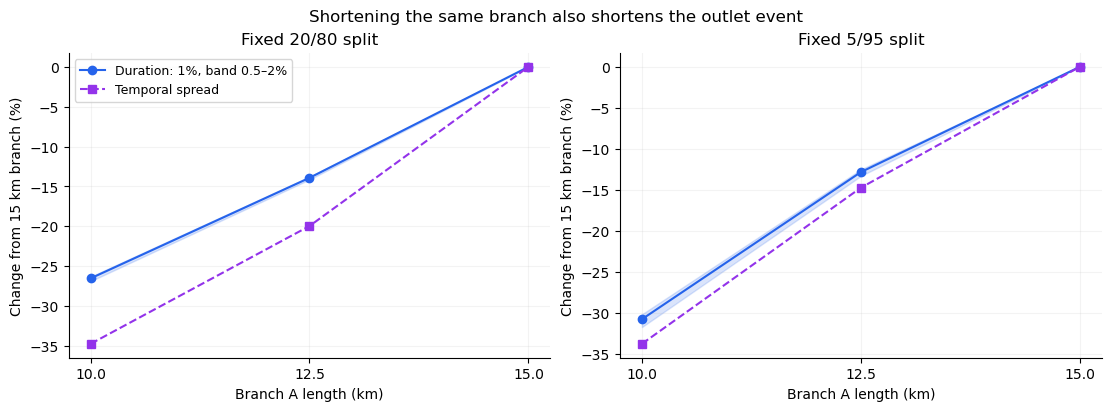

,outer_a_fraction,length_multiplier,duration_change_pct,temporal_spread_change_pct,lag_shift_pct,peak_excess_change_pct
61,0.20,1.50,0.00,0.00,0.00,0.00
64,0.20,1.25,-13.92,-19.96,0.00,0.02
67,0.20,1.00,-26.53,-34.74,2.94,3.27
70,0.05,1.50,0.00,0.00,0.00,0.00
73,0.05,1.25,-12.82,-14.72,0.00,0.00
76,0.05,1.00,-30.74,-33.74,0.00,0.00


In [4]:
short=d[d.kind=='shortening']
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,a in zip(axes,[.2,.05]):
    g=short[short.outer_a_fraction==a]
    w=g.pivot(index='length_multiplier',columns='threshold_fraction',values='duration_change_pct').sort_index()
    ax.fill_between(w.index*10,w.min(axis=1),w.max(axis=1),color='#2563eb',alpha=.17)
    ax.plot(w.index*10,w[.01],'-o',color='#2563eb',label='Duration: 1%, band 0.5–2%')
    one=g[g.threshold_fraction==.01].sort_values('length_multiplier')
    ax.plot(one.length_multiplier*10,one.temporal_spread_change_pct,'--s',color='#9333ea',label='Temporal spread')
    ax.set(title=f'Fixed {a*100:g}/{(1-a)*100:g} split',xlabel='Branch A length (km)',ylabel='Change from 15 km branch (%)',xticks=[10,12.5,15])
axes[0].legend(fontsize=9);fig.suptitle('Shortening the same branch also shortens the outlet event')
fig.savefig(OUT/'shortening_duration.png',dpi=160);display(fig);plt.close(fig)
display(short[short.threshold_fraction==.01][['outer_a_fraction','length_multiplier','duration_change_pct','temporal_spread_change_pct','lag_shift_pct','peak_excess_change_pct']].round(2))

## Decision supported by this verification

Use **1% plateau-to-plateau duration change** as the main overall event-length response, alongside lag shift and peak-excess change. Keep the 0.5% and 2% endpoints as a sensitivity check. Duration detects widening and delayed peaks above the tolerance, and it ignores a pure translation of the event.

It cannot say whether an event has one broad peak or two separated peaks with the same boundaries. Keep peak count or representative hydrographs for that distinction. A pulse below the tolerance is deliberately ignored; much narrower branches than those tested may therefore behave differently.

This verifies the metric on the focused synthetic examples. It **does not establish that the full seven-factor sensitivity rankings or real-case predictor fits remain the same**. Those analyses still need to be recomputed with duration as their response. The implementation supports separate initial and final plateaus, but this check only tests the equal-plateau synthetic case.